# Step 6 — Interactive Visualization with Plotly

Pure Python Data Analytics using **Plotly**.

This notebook creates interactive charts and a standalone HTML analytics dashboard. It does not use Machine Learning, Power BI, or Tableau.

### Included
- KPI cards
- Interactive performance distribution
- Study time analysis
- Absence vs grade scatter plot
- Previous failures analysis
- Parent education analysis
- School and gender comparison
- Interactive correlation heatmap
- Interactive multi-factor analysis
- Standalone HTML dashboard export


In [1]:
import os
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option('display.max_columns', None)

df = pd.read_csv('../data/student_performance_cleaned.csv')

print('Dataset shape:', df.shape)
df.head()

Dataset shape: (395, 35)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance_category,pass
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Fail,Fail
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Fail,Fail
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Average,Pass
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Good,Pass
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Average,Pass


## 1. Prepare Analytics Features

In [2]:
# Recreate analysis features so this notebook can run independently.
if 'performance_category' not in df.columns:
    def performance_category(score):
        if score < 10:
            return 'Fail'
        elif score < 14:
            return 'Average'
        elif score < 17:
            return 'Good'
        else:
            return 'Excellent'

    df['performance_category'] = df['G3'].apply(performance_category)

df['pass'] = np.where(df['G3'] >= 10, 'Pass', 'Fail')

df['absence_group'] = pd.cut(
    df['absences'],
    bins=[-1, 5, 10, 20, np.inf],
    labels=['Low (0–5)', 'Moderate (6–10)', 'High (11–20)', 'Very High (21+)']
)

df['study_time_label'] = df['studytime'].map({
    1: '<2 hours',
    2: '2–5 hours',
    3: '5–10 hours',
    4: '>10 hours'
})

df['parent_education'] = df['Medu'] + df['Fedu']

print('Features prepared successfully.')

Features prepared successfully.


## 2. KPI Cards

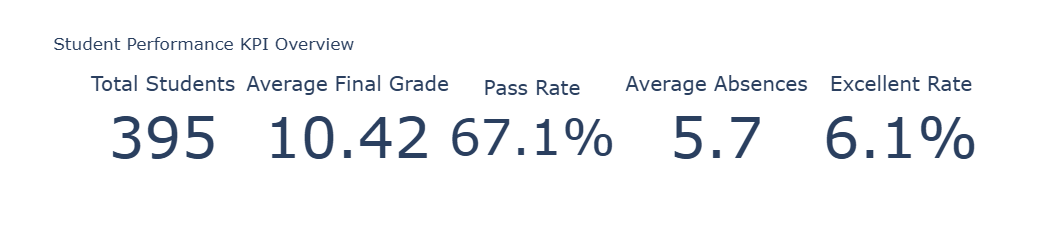

In [3]:
total_students = len(df)
avg_grade = df['G3'].mean()
pass_rate = (df['G3'] >= 10).mean() * 100
avg_absences = df['absences'].mean()
excellent_rate = (df['G3'] >= 17).mean() * 100

fig = go.Figure()

kpis = [
    ('Total Students', f'{total_students:,}'),
    ('Average Final Grade', f'{avg_grade:.2f}'),
    ('Pass Rate', f'{pass_rate:.1f}%'),
    ('Average Absences', f'{avg_absences:.1f}'),
    ('Excellent Rate', f'{excellent_rate:.1f}%')
]

for i, (label, value) in enumerate(kpis):
    fig.add_trace(go.Indicator(
        mode='number',
        value=float(str(value).replace('%','').replace(',','')) if label not in ['Pass Rate','Excellent Rate'] else float(value.replace('%','')),
        number={'suffix': '%' if '%' in value else ''},
        title={'text': label},
        domain={'row': 0, 'column': i}
    ))

fig.update_layout(
    grid={'rows': 1, 'columns': 5},
    height=250,
    title='Student Performance KPI Overview'
)
fig.show()

## 3. Interactive Performance Distribution

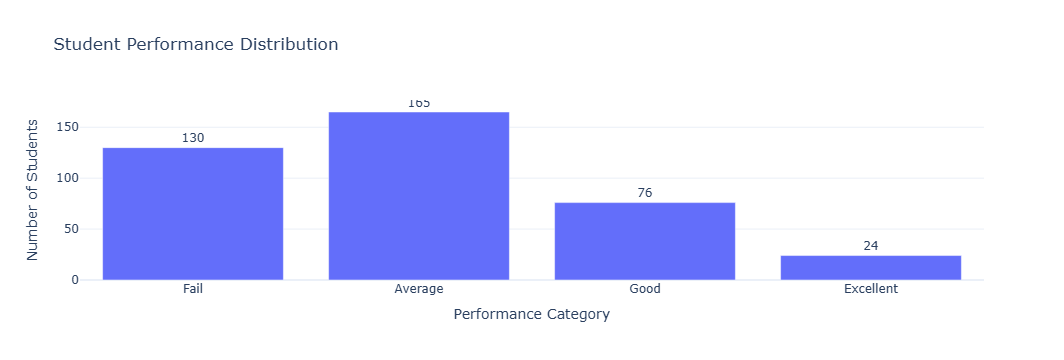

In [4]:
performance_order = ['Fail', 'Average', 'Good', 'Excellent']
performance_counts = (
    df['performance_category']
      .value_counts()
      .reindex(performance_order, fill_value=0)
      .reset_index()
)
performance_counts.columns = ['Performance Category', 'Students']

fig = px.bar(
    performance_counts,
    x='Performance Category',
    y='Students',
    text='Students',
    title='Student Performance Distribution',
    hover_data={'Students': True}
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', yaxis_title='Number of Students')
fig.show()

## 4. Study Time vs Final Grade

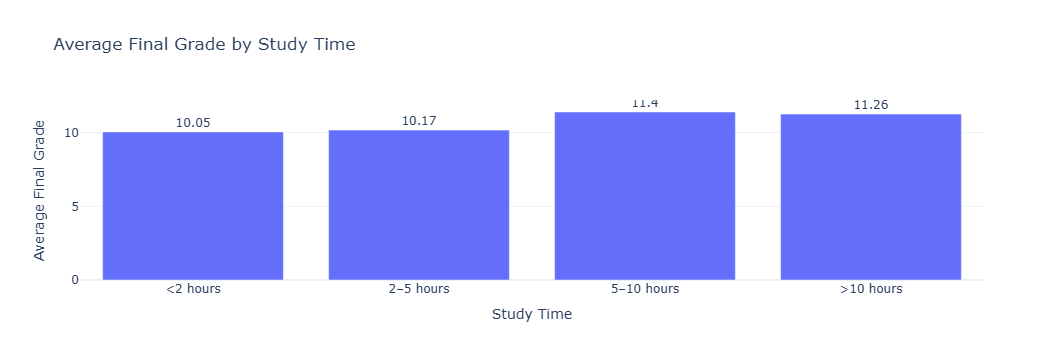

In [5]:
study_summary = (
    df.groupby(['studytime','study_time_label'], as_index=False)
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100)
      )
      .sort_values('studytime')
)

fig = px.bar(
    study_summary,
    x='study_time_label',
    y='Average_Grade',
    text=study_summary['Average_Grade'].round(2),
    hover_data=['Students','Pass_Rate'],
    title='Average Final Grade by Study Time',
    labels={'study_time_label':'Study Time','Average_Grade':'Average Final Grade'}
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white')
fig.show()

## 5. Absences vs Final Grade — Interactive Scatter

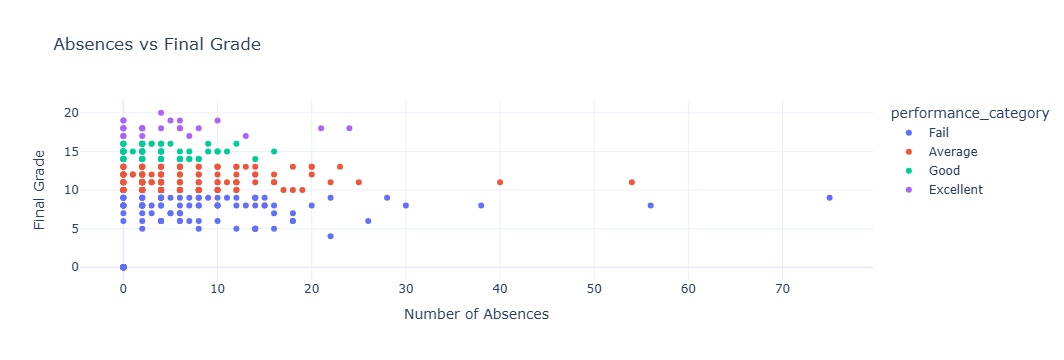

In [6]:
fig = px.scatter(
    df,
    x='absences',
    y='G3',
    color='performance_category',
    hover_data=['school','sex','study_time_label','failures'],
    title='Absences vs Final Grade',
    labels={'absences':'Number of Absences','G3':'Final Grade'}
)
fig.update_layout(template='plotly_white')
fig.show()

## 6. Previous Failures vs Performance

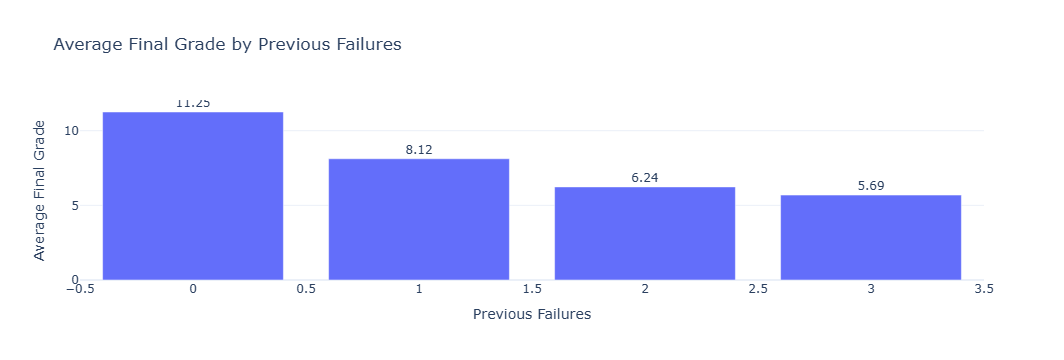

In [7]:
failure_summary = (
    df.groupby('failures', as_index=False)
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100)
      )
)

fig = px.bar(
    failure_summary,
    x='failures',
    y='Average_Grade',
    text=failure_summary['Average_Grade'].round(2),
    hover_data=['Students','Pass_Rate'],
    title='Average Final Grade by Previous Failures',
    labels={'failures':'Previous Failures','Average_Grade':'Average Final Grade'}
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white')
fig.show()

## 7. Parent Education vs Final Grade

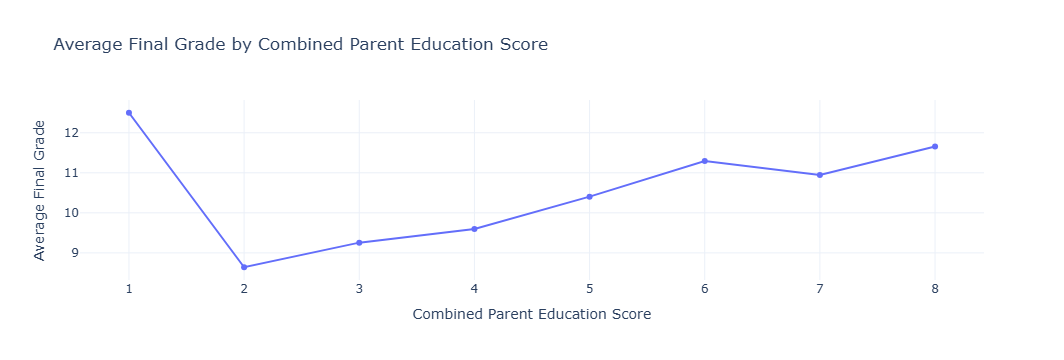

In [8]:
parent_summary = (
    df.groupby('parent_education', as_index=False)
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100)
      )
)

fig = px.line(
    parent_summary,
    x='parent_education',
    y='Average_Grade',
    markers=True,
    hover_data=['Students','Pass_Rate'],
    title='Average Final Grade by Combined Parent Education Score',
    labels={'parent_education':'Combined Parent Education Score','Average_Grade':'Average Final Grade'}
)
fig.update_layout(template='plotly_white')
fig.show()

## 8. School and Gender Comparison

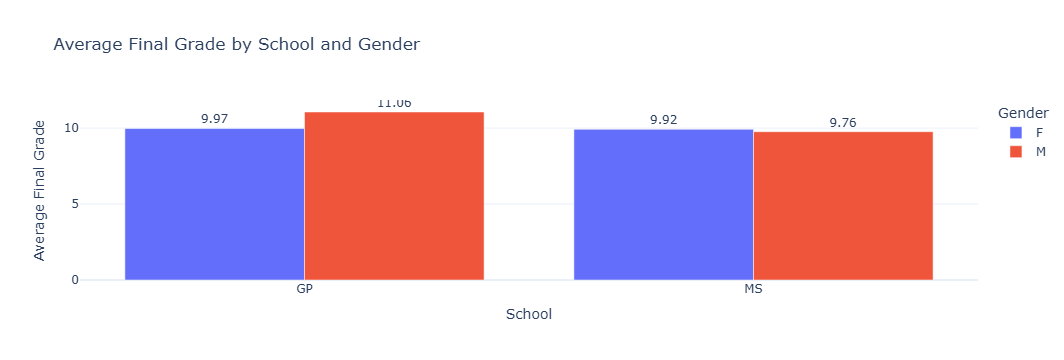

In [9]:
group_summary = (
    df.groupby(['school','sex'], as_index=False)
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100)
      )
)

fig = px.bar(
    group_summary,
    x='school',
    y='Average_Grade',
    color='sex',
    barmode='group',
    text=group_summary['Average_Grade'].round(2),
    hover_data=['Students','Pass_Rate'],
    title='Average Final Grade by School and Gender',
    labels={'school':'School','Average_Grade':'Average Final Grade','sex':'Gender'}
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white')
fig.show()

## 9. Interactive Correlation Heatmap

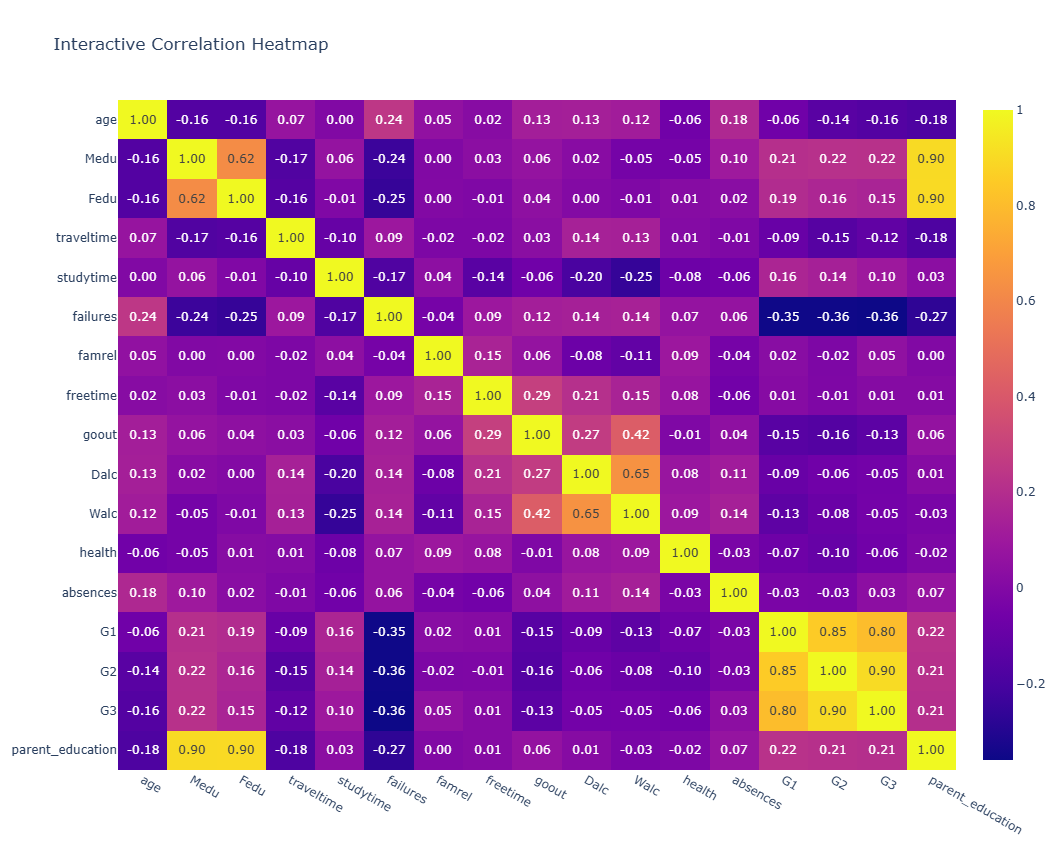

In [10]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

fig = px.imshow(
    corr,
    text_auto='.2f',
    aspect='auto',
    title='Interactive Correlation Heatmap'
)
fig.update_layout(template='plotly_white', height=850)
fig.show()

## 10. Study Time × Previous Failures

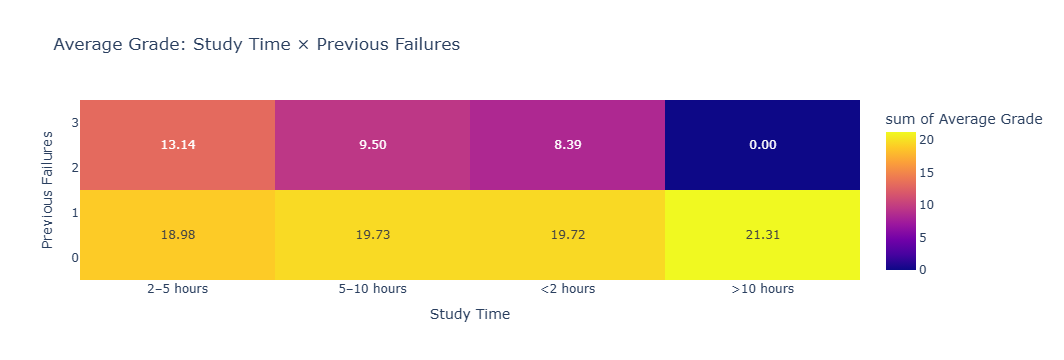

In [11]:
cross_summary = (
    df.groupby(['study_time_label','failures'], as_index=False)
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100)
      )
)

fig = px.density_heatmap(
    cross_summary,
    x='study_time_label',
    y='failures',
    z='Average_Grade',
    text_auto='.2f',
    title='Average Grade: Study Time × Previous Failures',
    labels={'study_time_label':'Study Time','failures':'Previous Failures','Average_Grade':'Average Grade'}
)
fig.update_layout(template='plotly_white')
fig.show()

## 11. Interactive Performance Profile

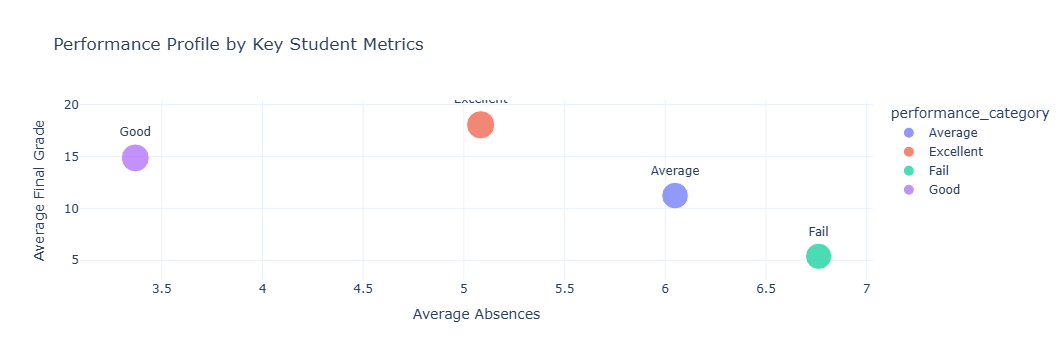

In [12]:
profile = (
    df.groupby('performance_category', as_index=False)
      .agg(
          Study_Time=('studytime','mean'),
          Absences=('absences','mean'),
          Previous_Failures=('failures','mean'),
          Parent_Education=('parent_education','mean'),
          Final_Grade=('G3','mean')
      )
)

fig = px.scatter(
    profile,
    x='Absences',
    y='Final_Grade',
    size='Study_Time',
    color='performance_category',
    hover_data=['Previous_Failures','Parent_Education'],
    text='performance_category',
    title='Performance Profile by Key Student Metrics',
    labels={'Absences':'Average Absences','Final_Grade':'Average Final Grade','Study_Time':'Average Study Time'}
)
fig.update_traces(textposition='top center')
fig.update_layout(template='plotly_white')
fig.show()

## 12. Export Interactive Charts to HTML

In [13]:
os.makedirs('../visualizations', exist_ok=True)

# Recreate the main charts and export each as a standalone HTML file.

fig1 = px.bar(
    performance_counts, x='Performance Category', y='Students', text='Students',
    title='Student Performance Distribution'
)
fig1.update_traces(textposition='outside')
fig1.write_html('../visualizations/performance_distribution.html')

fig2 = px.bar(
    study_summary, x='study_time_label', y='Average_Grade',
    text=study_summary['Average_Grade'].round(2), hover_data=['Students','Pass_Rate'],
    title='Average Final Grade by Study Time'
)
fig2.update_traces(textposition='outside')
fig2.write_html('../visualizations/study_time_analysis.html')

fig3 = px.scatter(
    df, x='absences', y='G3', color='performance_category',
    hover_data=['school','sex','study_time_label','failures'],
    title='Absences vs Final Grade'
)
fig3.write_html('../visualizations/absences_vs_grade.html')

fig4 = px.imshow(corr, text_auto='.2f', aspect='auto', title='Correlation Heatmap')
fig4.write_html('../visualizations/correlation_heatmap.html')

print('Interactive HTML visualizations exported successfully.')

Interactive HTML visualizations exported successfully.


## Step 6 Complete

You now have interactive Plotly analytics that can be opened directly in a browser.

### Output folder
`visualizations/`

### Main exported files
- `performance_distribution.html`
- `study_time_analysis.html`
- `absences_vs_grade.html`
- `correlation_heatmap.html`

These files are standalone HTML visualizations and can be shared without Power BI or Tableau.
